<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/task7_sales_forecasting/Sales_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 7: Sales Forecasting

**Goal:** Predict future weekly sales from historical sales data.

**Dataset:** Walmart Dataset (Kaggle, by yasserh), weekly sales for 45 stores.

**Tools:** Python, Pandas, Matplotlib, Scikit-learn, XGBoost

In [1]:
import pandas as pd

## Load the dataset

In [2]:
df = pd.read_csv('/content/Walmart.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [3]:
df.shape

(6435, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


## Data Cleaning

In [5]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

In [8]:
print(df["Date"].dtype)
print(df["Date"].min(), "to", df["Date"].max())

datetime64[ns]
2010-02-05 00:00:00 to 2012-10-26 00:00:00


In [9]:
df['Date'].head()

,Date
0,2010-02-05
1,2010-02-12
2,2010-02-19
3,2010-02-26
4,2010-03-05


In [10]:
df.nunique()

,0
Store,45
Date,143
Weekly_Sales,6435
Holiday_Flag,2
Temperature,3528
Fuel_Price,892
CPI,2145
Unemployment,349


In [11]:
(df["Weekly_Sales"] < 0).sum()

np.int64(0)

In [12]:
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

In [13]:
print(df.head(3)[["Store", "Date"]])
print("Sorted by store and date:", df[["Store", "Date"]].equals(df[["Store", "Date"]].sort_values(["Store", "Date"]).reset_index(drop=True)))

   Store       Date
0      1 2010-02-05
1      1 2010-02-12
2      1 2010-02-19
Sorted by store and date: True


### Observation: Data Cleaning

The dataset has 6,435 rows and 8 columns with no missing values, no duplicate rows and no negative sales. It covers 45 stores over 143 weekly dates (5 Feb 2010 to 26 Oct 2012), so every store has a complete weekly series with no gaps. Date was converted to datetime, and the data was sorted by store and date so that lag features and the time-based split use the correct order. Since the data is weekly, I will create week, month and year features and lags, not day features.

In [14]:
Q1, Q3 = df["Weekly_Sales"].quantile([0.25, 0.75])
IQR = Q3 - Q1
low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers = df[(df["Weekly_Sales"] < low) | (df["Weekly_Sales"] > high)]
print("Outliers:", len(outliers), "out of", len(df))
print(outliers["Date"].dt.month.value_counts().sort_index())
print(outliers.groupby("Store")["Weekly_Sales"].count().sort_values(ascending=False).head())

Outliers: 34 out of 6435
Date
11     9
12    25
Name: count, dtype: int64
Store
20    7
13    6
4     6
10    5
14    4
Name: Weekly_Sales, dtype: int64


### Observation: Outliers

Some weeks have very high sales by the IQR rule, mostly in November and December and in the larger stores. These look like real holiday peaks and store-size differences, not errors, so I kept them because a forecasting model needs to learn these seasonal patterns.

## Exploratory Data Analysis(EDA)

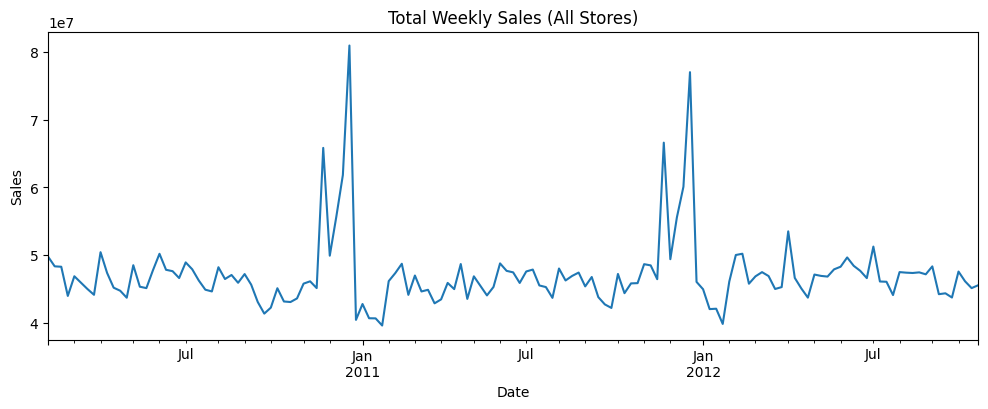

In [15]:
### Total Weekly Sales Over Time
import matplotlib.pyplot as plt
import seaborn as sns

total = df.groupby("Date")["Weekly_Sales"].sum()
plt.figure(figsize=(12, 4))
total.plot()
plt.title("Total Weekly Sales (All Stores)")
plt.ylabel("Sales")
plt.show()


### Observation: Total Weekly Sales Over Time

Total weekly sales stay fairly stable at about 40 to 50 million, with no clear long-term trend. There are sharp spikes at the end of each year, reaching about 81 million in December 2010 and 77 million in December 2011, with a smaller peak just before each one. These match the Thanksgiving and Christmas shopping seasons and repeat every year, which shows clear yearly seasonality. So time features such as week and month, plus lag values, should help the forecast.

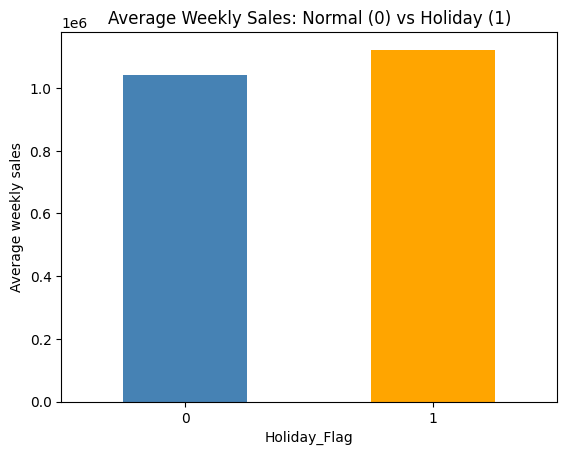

In [16]:
## Holiday Weeks vs Normal Weeks
df.groupby("Holiday_Flag")["Weekly_Sales"].mean().plot(kind="bar", color=["steelblue", "orange"])
plt.title("Average Weekly Sales: Normal (0) vs Holiday (1)")
plt.xticks(rotation=0)
plt.ylabel("Average weekly sales")
plt.show()